# Project: Spread of a Virus

In this project we simulate a virus spreading through a population of people moving around in a box.
Every person is an **object** of the class `person`. We will then use **inheritance** to build a new
kind of person, `quarantine_person`, who behaves the same as a `person` except that once they get sick
they are sent to quarantine.

**The model**
* $N$ people move in straight lines inside a $1\times 1$ box and bounce off the walls.
* One person starts out sick (red). Everyone else is healthy (black).
* A healthy person who comes within `safe_radius` of a sick person (in both $x$ and $y$) gets sick.
* After `sick_time` time steps, a sick person recovers and becomes immune (green).
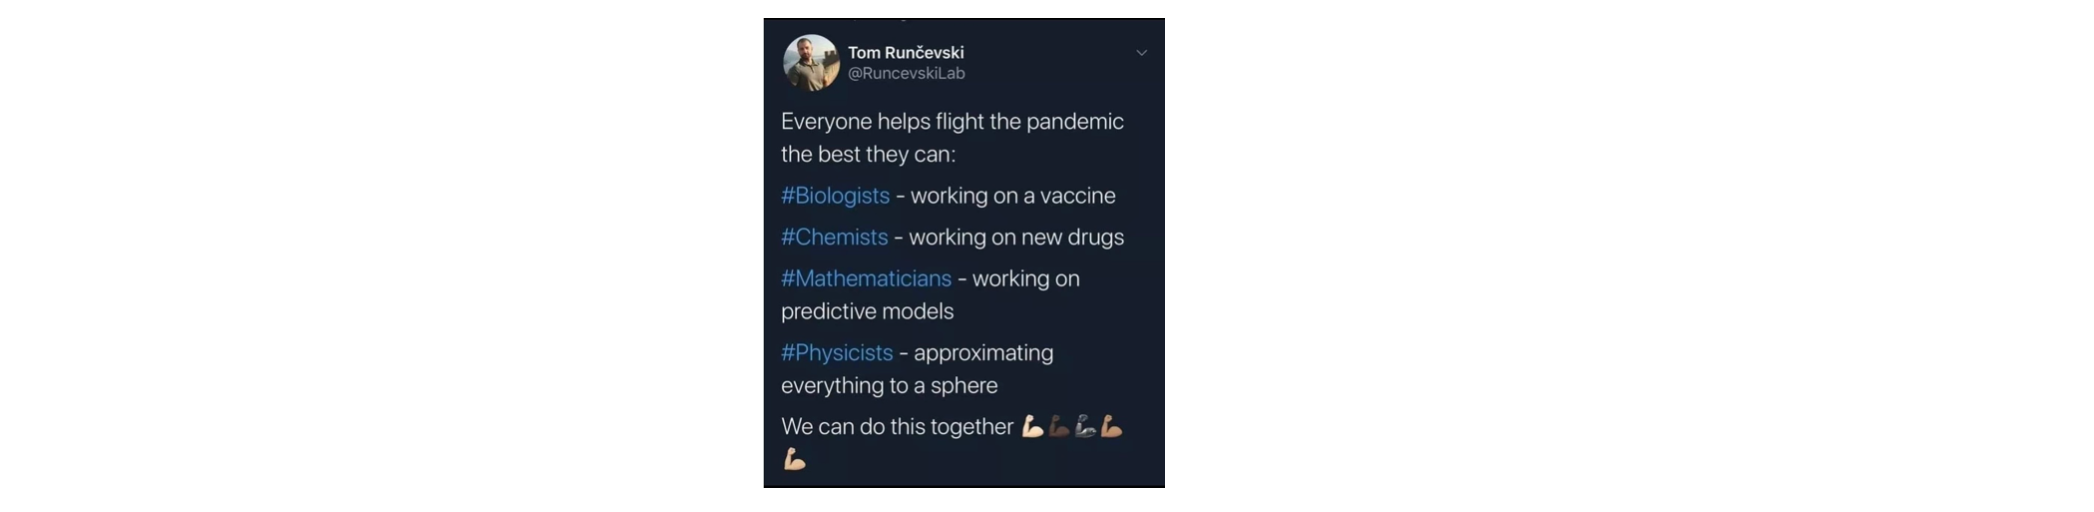

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as ani
from IPython.display import HTML
plt.rcParams['animation.embed_limit'] = 50

## The `person` class
* `sick = 0` means healthy; `sick > 0` counts the number of time steps the person has been sick.
* `move(dt)` moves the person, bounces them off the walls, and advances the sick counter.
* `get_sick(pop_sick, safe_radius)` makes the person sick if any sick person is too close.
* `get_immune(sick_time)` makes the person immune after they have been sick long enough.

In [2]:
class person():

    def __init__(self, box, sick, velocity):
        self.rng = np.random.default_rng()
        self.box = box
        # sick = 0 means healthy, sick > 0 counts the number of time steps sick
        self.sick = sick
        self.immune = False
        self.pos = self.rng.random(size=2) * box
        self.velocity = velocity * self.rng.uniform(-1, 1, size=2)

    def move(self, dt):
        self.pos += self.velocity * dt
        for direction in range(2):
            if self.pos[direction] < 0 or self.pos[direction] > self.box[direction]:
                self.velocity[direction] = -self.velocity[direction]
        if self.sick > 0:
            self.sick += 1

    def get_sick(self, pop_sick, safe_radius):
        for other in pop_sick:
            if abs(self.pos[0] - other.pos[0]) < safe_radius \
                and abs(self.pos[1] - other.pos[1]) < safe_radius:
                self.sick = 1

    def get_immune(self, sick_time):
        if self.sick > sick_time:
            self.immune = True

## Parameters

In [3]:
dt = 0.02               # time step
box = np.array([1, 1])  # size of the box
velocity = 1.           # maximum speed of a person
nhealthy = 200          # number of people who start healthy
nsick = 1               # number of people who start sick
safe_radius = 0.009     # infection distance
sick_time = 300         # number of time steps until a sick person becomes immune

## The simulation 

`run_simulation(pop_healthy, pop_sick)` takes a list of healthy people and a list of sick people,
and returns an animation together with the number of healthy, sick and immune people at every time step.

In [4]:
def run_simulation(pop_healthy, pop_sick, nframes=250, steps_per_frame=5):
    pop_healthy = np.array(pop_healthy)
    pop_sick = np.array(pop_sick)
    pop_immune = np.array([])

    time = [0.]
    traj_healthy = [len(pop_healthy)]
    traj_sick = [len(pop_sick)]
    traj_immune = [0]

    # --- figure: people in the box (top), number of people vs time (bottom)
    fig, axes = plt.subplots(2, figsize=(4, 8), dpi=60)
    axes[0].set_xlim(0, box[0])
    axes[0].set_ylim(0, box[1])
    axes[0].set_aspect('equal')
    axes[1].set_xlim(0, nframes * steps_per_frame * dt)
    axes[1].set_ylim(0, (len(pop_healthy) + len(pop_sick)) * 1.1)
    axes[1].set_xlabel('time')
    axes[1].set_ylabel('number of people')

    a, = axes[0].plot([], [], 'ko', ms=3)
    b, = axes[0].plot([], [], 'ro', ms=3)
    c, = axes[0].plot([], [], 'go', ms=3)
    pa, = axes[1].plot([], [], 'k-', label='healthy')
    pb, = axes[1].plot([], [], 'r-', label='sick')
    pc, = axes[1].plot([], [], 'g-', label='immune')
    axes[1].legend(loc='upper right')
    fig.tight_layout()

    def step():
        nonlocal pop_healthy, pop_sick, pop_immune

        # advance time
        time.append(time[-1] + dt)
        for p in pop_healthy:
            p.get_sick(pop_sick, safe_radius)
            p.move(dt)
        for p in pop_sick:
            p.get_immune(sick_time)
            p.move(dt)
        for p in pop_immune:
            p.move(dt)

        # healthy people who got sick move to the sick population
        idx = np.array([p.sick for p in pop_healthy]) == 0
        pop_sick = np.append(pop_sick, pop_healthy[np.invert(idx)])
        pop_healthy = pop_healthy[idx]

        # sick people who became immune move to the immune population
        idx = np.array([p.immune for p in pop_sick]) == False
        pop_immune = np.append(pop_immune, pop_sick[np.invert(idx)])
        pop_sick = pop_sick[idx]

        traj_healthy.append(len(pop_healthy))
        traj_sick.append(len(pop_sick))
        traj_immune.append(len(pop_immune))

    def init():
        return a, b, c, pa, pb, pc

    def animate(i):
        for _ in range(steps_per_frame):
            step()
        a.set_data([p.pos[0] for p in pop_healthy], [p.pos[1] for p in pop_healthy])
        b.set_data([p.pos[0] for p in pop_sick], [p.pos[1] for p in pop_sick])
        c.set_data([p.pos[0] for p in pop_immune], [p.pos[1] for p in pop_immune])
        pa.set_data(time, traj_healthy)
        pb.set_data(time, traj_sick)
        pc.set_data(time, traj_immune)
        return a, b, c, pa, pb, pc

    anim = ani.FuncAnimation(fig, animate, init_func=init, frames=nframes, interval=50)
    plt.close(fig)   
    return anim, time, traj_healthy, traj_sick, traj_immune


def summary(traj_healthy, traj_sick):
    print(f"peak number of sick people: {max(traj_sick)}")
    print(f"people never infected:      {traj_healthy[-1]}")

## No quarantine

Run the next cell. Rendering the animation takes a little while, so be patient.
**Record** the peak number of sick people and the number of people who were never infected.

In [ ]:
pop_healthy = [person(box, 0, velocity) for i in range(nhealthy)]
pop_sick    = [person(box, 1, velocity) for i in range(nsick)]

anim, time, traj_healthy, traj_sick, traj_immune = run_simulation(pop_healthy, pop_sick)
movie = HTML(anim.to_jshtml())   
summary(traj_healthy, traj_sick)
movie

## Quarantine

A `quarantine_person` is a `person` in every way except one: **as soon as they are sick, they are
sent to the quarantine area in the corner $(0,0)$ and stop moving.**

Because a `quarantine_person` *is a* `person`, it should **inherit** from `person`.
We only need to change the `move` method:

* **Step 1.** Put the parent class inside the parentheses of the class definition.
* **Step 2.** In `move`, first do everything a normal `person` does when moving, by calling the
  parent's `move` method with `super()`.
* **Step 3.** Then, if the person is sick, set their position to $(0,0)$ and their velocity to $(0,0)$.

In [ ]:
class quarantine_person(  ???  ):          # Step 1: which class is the parent?

    def move(self, dt):
        # Step 2: first call the parent's move method

        if self.sick > 0:
            # Step 3:
            # position of this person will move to (0,0)
            # velocity of this person will change to (0,0)


* **Step 4.**  Run with quarantined people. Create the populations from `quarantine_person` instead of `person`, then run the cell. Note the peak number of sick people and the number of people who were never infected.

In [ ]:
# Step 4: replace ??? so that both populations are made of quarantine_person
pop_healthy = [ ??? (box, 0, velocity) for i in range(nhealthy)]
pop_sick    = [ ??? (box, 1, velocity) for i in range(nsick)]

anim_q, time_q, healthy_q, sick_q, immune_q = run_simulation(pop_healthy, pop_sick)
movie_q = HTML(anim_q.to_jshtml())
summary(healthy_q, sick_q)
movie_q


1. How did quarantine change the peak number of sick people, and the number of people who were never infected?
2. Where do the sick people end up in the animation? Quarantined people do not move, so how can healthy people still get infected?
